In [469]:
import catboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False#图像显示
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# ========== 就放这里：导入完库，直接定义编码器类 ==========
class SmoothTargetEncoder:
    def __init__(self, cols, smooth=10):
        self.cols = cols
        self.smooth = smooth
        self.enc_maps = {}
        self.global_mean = None

    def fit(self, X, y):
        self.global_mean = y.mean()
        for col in self.cols:
            stats = pd.DataFrame({'x': X[col], 'y': y}).groupby('x')['y'].agg(['count', 'mean'])
            self.enc_maps[col] = ((stats['count']*stats['mean'] + self.smooth*self.global_mean)
                                  / (stats['count']+self.smooth)).to_dict()
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.cols:
            X[f'{col}_enc'] = X[col].map(self.enc_maps[col]).fillna(self.global_mean)
            X.drop(col, axis=1, inplace=True)
        return X


In [470]:
df = (pd.read_csv('hotel_bookings.csv'))
# 需要删除的全部特征
drop_cols = [

    'reservation_status',
     'reservation_status_date',
    'booking_changes',
    'assigned_room_type',
    'days_in_waiting_list',
    'arrival_date_year',
    'meal',
]

# 删除列
df = df.drop(columns=drop_cols)
# 直接在df上过滤（业务逻辑过滤，无泄露）
df = df[~((df['adr'] <= 0) | ((df.adults==0) & (df.children==0) & (df.babies==0)))]


#缺失值处理
fill_cols = ['country', 'agent', 'company']
for col in fill_cols:
    df[col] = df[col].fillna('Unknown')



In [471]:
df['children'] = df['children'].fillna(0)
#预定时长*入住天数
df['stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['lead_stay'] = df['lead_time'] * df['stay_nights']

#2 人均房价（排除婴儿）
df['price_per_pay_guest'] = df['adr'] / (df['adults'] + df['children'])



In [472]:
#模型建立
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. 构建X、y
X = df.drop(columns = ['is_canceled'])
y = df['is_canceled']
# ---------------------- 划分数据集 ----------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


# ========== 2. 特征分组 ==========
long_tail_cols = ['country', 'agent', 'company']  # 长尾：目标编码
# 长尾特征目标编码
enc = SmoothTargetEncoder(cols=['country', 'agent', 'company'], smooth=10)
enc.fit(X_train, y_train)
X_train_enc = enc.transform(X_train)
X_test_enc = enc.transform(X_test)

# 自动对剩余所有分类列做独热编码
X_train_final = pd.get_dummies(X_train_enc, drop_first=True)
X_test_final = pd.get_dummies(X_test_enc, drop_first=True)

# 列对齐
X_test_final = X_test_final.reindex(columns=X_train_final.columns, fill_value=0)

========= 逻辑回归 模型指标 =========
准确率 Accuracy: 0.8165
精确率 Precision: 0.8068
召回率 Recall: 0.6713
F1分数 F1-score: 0.7329
AUC值: 0.8977
混淆矩阵：
[[13263  1415]
 [ 2893  5909]]


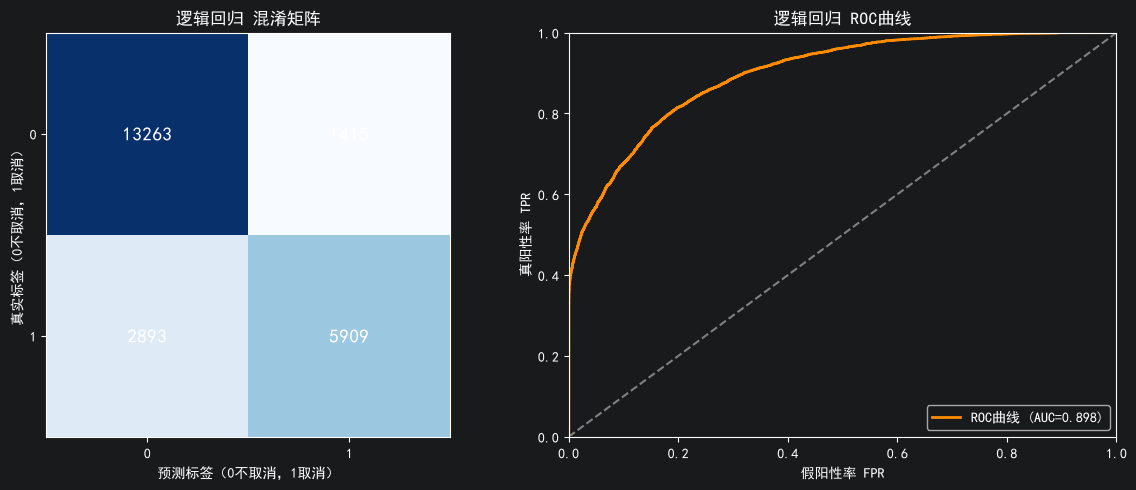

In [473]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)
import matplotlib.pyplot as plt

# ---------------------- 标准化（逻辑回归必备） ----------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

# ---------------------- 训练逻辑回归 ----------------------
lr = LogisticRegression(max_iter=2000, random_state=42)
lr.fit(X_train_scaled, y_train)

# 预测
y_pred = lr.predict(X_test_scaled)  # 0/1预测标签
y_pred_proba = lr.predict_proba(X_test_scaled)[:, 1]  # 预测为取消的概率

# ---------------------- 输出关键评价指标 ----------------------
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

print("========= 逻辑回归 模型指标 =========")
print(f"准确率 Accuracy: {acc:.4f}")
print(f"精确率 Precision: {prec:.4f}")
print(f"召回率 Recall: {rec:.4f}")
print(f"F1分数 F1-score: {f1:.4f}")
print(f"AUC值: {roc_auc:.4f}")
print("混淆矩阵：")
print(cm)

# ---------------------- 绘图：混淆矩阵 + ROC曲线 ----------------------
plt.rcParams['font.sans-serif'] = ['SimHei']  # 中文
plt.rcParams['axes.unicode_minus'] = False
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 混淆矩阵
im = ax1.imshow(cm, cmap='Blues')
ax1.set_title('逻辑回归 混淆矩阵')
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xlabel('预测标签（0不取消，1取消）')
ax1.set_ylabel('真实标签（0不取消，1取消）')
for i in range(2):
    for j in range(2):
        ax1.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14)

# ROC曲线
ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC曲线 (AUC={roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1])
ax2.set_xlabel('假阳性率 FPR')
ax2.set_ylabel('真阳性率 TPR')
ax2.set_title('逻辑回归 ROC曲线')
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()


========= 随机森林 模型指标 =========
准确率 Accuracy: 0.8923
精确率 Precision: 0.8811
召回率 Recall: 0.8240
F1分数 F1-score: 0.8516
AUC值: 0.9595
混淆矩阵：
[[13699   979]
 [ 1549  7253]]


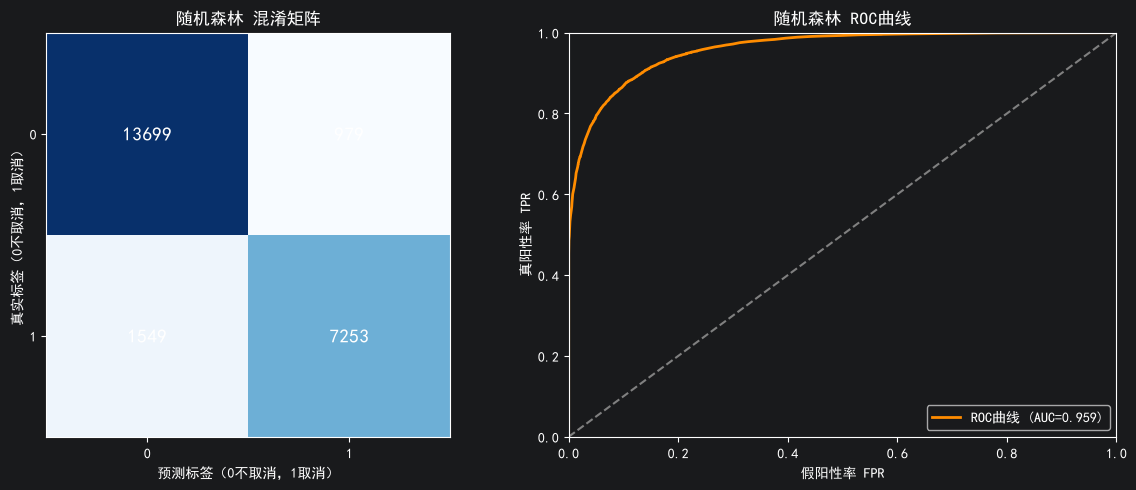

                      feature  importance
17                country_enc    0.121103
51    deposit_type_Non Refund    0.087003
0                   lead_time    0.086229
15                  lead_stay    0.083358
18                  agent_enc    0.077816
13  total_of_special_requests    0.059298
11                        adr    0.055916
16        price_per_pay_guest    0.054722
2   arrival_date_day_of_month    0.043695
1    arrival_date_week_number    0.040446


In [474]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)
import matplotlib.pyplot as plt
import pandas as pd

# 训练随机森林
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
# 修改1：用编码后的最终训练集训练
rf.fit(X_train_final, y_train)

# 修改2：用编码后的最终测试集预测
y_pred_rf = rf.predict(X_test_final)
y_pred_proba_rf = rf.predict_proba(X_test_final)[:,1]

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

print("========= 随机森林 模型指标 =========")
print(f"准确率 Accuracy: {acc_rf:.4f}")
print(f"精确率 Precision: {prec_rf:.4f}")
print(f"召回率 Recall: {rec_rf:.4f}")
print(f"F1分数 F1-score: {f1_rf:.4f}")
print(f"AUC值: {roc_auc_rf:.4f}")
print("混淆矩阵：")
print(cm_rf)

# 绘图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(12,5))

# 混淆矩阵
im = ax1.imshow(cm_rf, cmap='Blues')
ax1.set_title('随机森林 混淆矩阵')
ax1.set_xticks([0,1])
ax1.set_yticks([0,1])
ax1.set_xlabel('预测标签（0不取消，1取消）')
ax1.set_ylabel('真实标签（0不取消，1取消）')
for i in range(2):
    for j in range(2):
        ax1.text(j,i,str(cm_rf[i,j]),ha="center",va="center",fontsize=14)

# ROC
ax2.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f'ROC曲线 (AUC={roc_auc_rf:.3f})')
ax2.plot([0,1],[0,1], color='gray', linestyle='--')
ax2.set_xlim([0,1])
ax2.set_ylim([0,1])
ax2.set_xlabel('假阳性率 FPR')
ax2.set_ylabel('真阳性率 TPR')
ax2.set_title('随机森林 ROC曲线')
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 输出特征重要性
# 修改3：用编码后的最终特征列名，匹配实际输入特征
feature_importance = pd.DataFrame({
    'feature': X_train_final.columns,
    'importance': rf.feature_importances_
}).sort_values('importance',ascending=False)
print(feature_importance.head(10))


========= XGBoost 模型指标 =========
准确率 Accuracy: 0.8746
精确率 Precision: 0.8519
召回率 Recall: 0.8055
F1分数 F1-score: 0.8280
AUC值: 0.9485
混淆矩阵：
[[13445  1233]
 [ 1712  7090]]


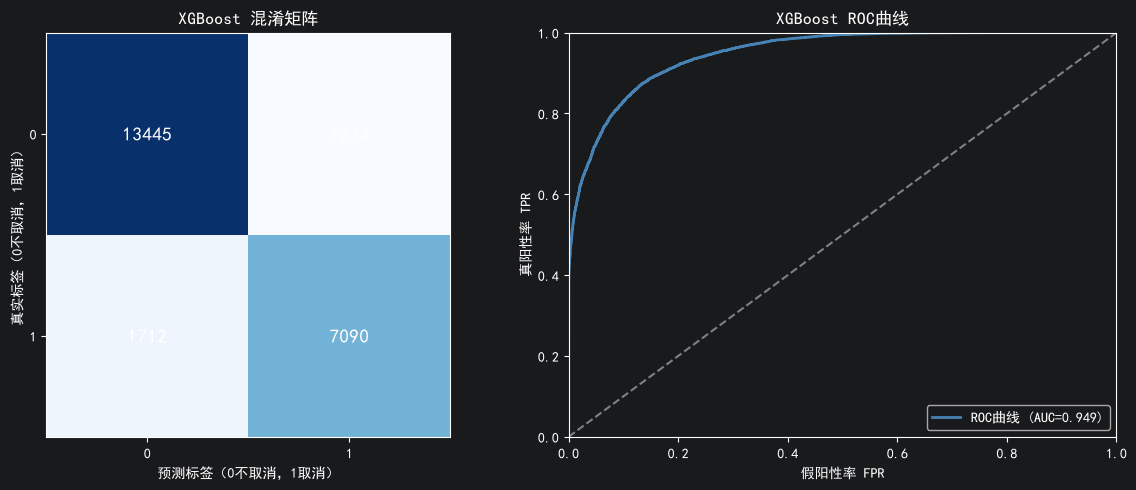


XGBoost Top10特征重要性：
                          feature  importance
51        deposit_type_Non Refund    0.657409
12    required_car_parking_spaces    0.055961
55  customer_type_Transient-Party    0.028995
9          previous_cancellations    0.022821
17                    country_enc    0.021288
13      total_of_special_requests    0.021123
18                      agent_enc    0.019389
37       market_segment_Online TA    0.017351
34          market_segment_Direct    0.012337
41     distribution_channel_TA/TO    0.011384


In [475]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc
)
import matplotlib.pyplot as plt
import pandas as pd

# 构建模型
xgb_model = XGBClassifier(
    random_state=42,
    verbosity=0,  # 关闭训练日志
    eval_metric="logloss",
    use_label_encoder=False
)

#修改为编码完成后的训练集
xgb_model.fit(X_train_final, y_train)

#修改为编码完成后的测试集
y_pred_xgb = xgb_model.predict(X_test_final)
y_pred_proba_xgb = xgb_model.predict_proba(X_test_final)[:, 1]

# 指标计算
acc_xgb = accuracy_score(y_test, y_pred_xgb)
prec_xgb = precision_score(y_test, y_pred_xgb)
rec_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

print("========= XGBoost 模型指标 =========")
print(f"准确率 Accuracy: {acc_xgb:.4f}")
print(f"精确率 Precision: {prec_xgb:.4f}")
print(f"召回率 Recall: {rec_xgb:.4f}")
print(f"F1分数 F1-score: {f1_xgb:.4f}")
print(f"AUC值: {roc_auc_xgb:.4f}")
print("混淆矩阵：")
print(cm_xgb)

# 绘图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 混淆矩阵
im = ax1.imshow(cm_xgb, cmap='Blues')
ax1.set_title('XGBoost 混淆矩阵')
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xlabel('预测标签（0不取消，1取消）')
ax1.set_ylabel('真实标签（0不取消，1取消）')
for i in range(2):
    for j in range(2):
        ax1.text(j, i, str(cm_xgb[i, j]), ha="center", va="center", fontsize=14)

# ROC
ax2.plot(fpr_xgb, tpr_xgb, color='steelblue', lw=2, label=f'ROC曲线 (AUC={roc_auc_xgb:.3f})')
ax2.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1])
ax2.set_xlabel('假阳性率 FPR')
ax2.set_ylabel('真阳性率 TPR')
ax2.set_title('XGBoost ROC曲线')
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

# 特征重要性
feature_importance_xgb = pd.DataFrame({
    'feature': X_train_final.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nXGBoost Top10特征重要性：")
print(feature_importance_xgb.head(10))




In [476]:
#ACC 准确率，判断对的比例
#Pre 精确率，预测为正类的样本中，正类实际的占比   有没有乱报
#Recall 召回率，所有正类被判断对的比例  有没有漏太多
#AOc，整体打分能力，也就是说越大，模型的区分能力更好
#F1 在精确率和召回率之间取一个平衡， 判断报的准和抓的全的综合能力


In [477]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,auc,roc_curve

# ========== GB模型 ==========
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# 5折分层交叉验证（和RF完全一样设置）
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ['accuracy','precision','recall','f1','roc_auc']

cv_result = cross_validate(
    estimator=gb,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 输出5折均值±标准差
print("====训练集5折交叉验证【GB】====")
for metric in scoring_metrics:
    scores = cv_result[f'test_{metric}']
    print(f"{metric}: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 独立测试集评估
gb.fit(X_train_final, y_train)
y_pred_gb = gb.predict(X_test_final)
y_pred_proba_gb = gb.predict_proba(X_test_final)[:,1]

acc_gb = accuracy_score(y_test, y_pred_gb)
prec_gb = precision_score(y_test, y_pred_gb)
rec_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_proba_gb)
roc_auc_gb = auc(fpr_gb, tpr_gb)

print("\n====独立测试集【GB】====")
print(f"Accuracy: {acc_gb:.4f}")
print(f"Precision: {prec_gb:.4f}")
print(f"Recall: {rec_gb:.4f}")
print(f"F1: {f1_gb:.4f}")
print(f"AUC: {roc_auc_gb:.4f}")


====训练集5折交叉验证【GB】====
accuracy: 0.8436 ± 0.0007
precision: 0.8224 ± 0.0017
recall: 0.7434 ± 0.0026
f1: 0.7809 ± 0.0013
roc_auc: 0.9250 ± 0.0014

====独立测试集【GB】====
Accuracy: 0.8483
Precision: 0.8254
Recall: 0.7552
F1: 0.7887
AUC: 0.9301


In [478]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,auc,roc_curve

# ========== 用sklearn默认参数，不使用之前调出来的最优参数 ==========
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# 5折分层交叉验证（仅在训练集内部做！）
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ['accuracy','precision','recall','f1','roc_auc']

cv_result = cross_validate(
    estimator=rf,
    X=X_train_final,
    y=y_train,
    cv=cv,
    scoring=scoring_metrics,
    return_train_score=False
)

# 输出5折均值±标准差，看波动大小（判断偶然性）
print("====训练集5折交叉验证【默认参数RF】====")
for metric in scoring_metrics:
    scores = cv_result[f'test_{metric}']
    print(f"{metric}: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 最后在独立测试集评估（只跑一次）
rf.fit(X_train_final, y_train)
y_pred_rf = rf.predict(X_test_final)
y_pred_proba_rf = rf.predict_proba(X_test_final)[:,1]

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

print("\n====独立测试集【默认参数RF】====")
print(f"Accuracy: {acc_rf:.4f}")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall: {rec_rf:.4f}")
print(f"F1: {f1_rf:.4f}")
print(f"AUC: {roc_auc_rf:.4f}")


# 在RF训练完之后运行，找最优阈值
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_rf)
# 选约登指数最大的阈值
J = tpr - fpr
best_idx = np.argmax(J)
best_thresh = thresholds[best_idx]
print(f"最优阈值：{best_thresh:.4f}")

# 使用新阈值预测
y_pred_rf_new = (y_pred_proba_rf >= best_thresh).astype(int)

# 重新评估
acc_rf_new = accuracy_score(y_test, y_pred_rf_new)
prec_rf_new = precision_score(y_test, y_pred_rf_new)
rec_rf_new = recall_score(y_test, y_pred_rf_new)
f1_rf_new = f1_score(y_test, y_pred_rf_new)
print(f"\n阈值调整后 RF Test Acc：{acc_rf_new:.4f}")
print(f"Precision: {prec_rf_new:.4f}")
print(f"Recall: {rec_rf_new:.4f}")
print(f"F1: {f1_rf_new:.4f}")



====训练集5折交叉验证【默认参数RF】====
accuracy: 0.8836 ± 0.0010
precision: 0.8710 ± 0.0028
recall: 0.8095 ± 0.0049
f1: 0.8391 ± 0.0018
roc_auc: 0.9533 ± 0.0014

====独立测试集【默认参数RF】====
Accuracy: 0.8923
Precision: 0.8811
Recall: 0.8240
F1: 0.8516
AUC: 0.9595
最优阈值：0.4100

阈值调整后 RF Test Acc：0.8880
Precision: 0.8337
Recall: 0.8759
F1: 0.8543
